In [ ]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 12.7 MB/s eta 0:00:00


In [ ]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

# WIGNER FUNCTION

A more complete phase-space probability-distribution-like function for harmonic modes are the Wigner and Husumi Q-functions, which are full descriptions of the quantum state (equivalent to the density matrix). These are called **quasi-distribution functions** because unlike real probability distribution functions they can for example be negative. In addition to being more complete descriptions of a state (compared to only the occupation probabilities plotted above), these distributions are also great for demonstrating if a quantum state is quantum mechanical, since for example a **negative Wigner function** is a definite indicator that a state is distinctly nonclassical.

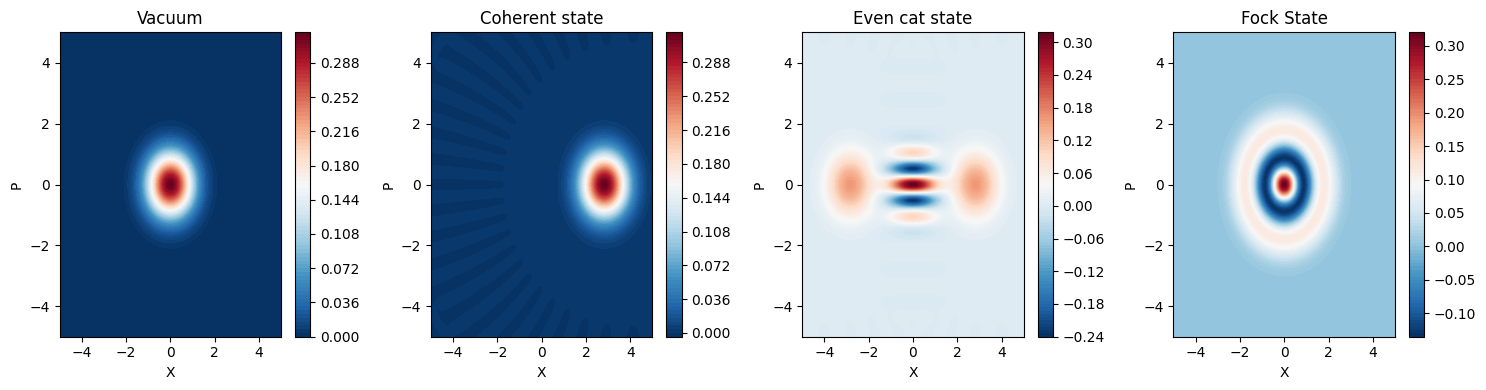

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from qutip import *



N = 30               # Hilbert space truncation, produce the lines in the plot
alpha = 2.0            # coherent state amplitude

x = np.linspace(-5,5,200)
p = np.linspace(-5,5,200)


# Vacuum
vac = basis(N,0)

# Coherent state
coh = coherent(N, alpha)

# Even cat state
cat = (coherent(N,alpha) + coherent(N,-alpha)).unit()

rho_fock = fock_dm(N, 2)


# Wigner functions

W_vac = wigner(vac, x, p)
W_coh = wigner(coh, x, p)
W_cat = wigner(cat, x, p)
W_fock = wigner(rho_fock, x, p)

fig, ax = plt.subplots(1,4,figsize=(15,4))

titles = [
    "Vacuum",
    "Coherent state",
    "Even cat state",
    "Fock State"
]

Ws = [W_vac, W_coh, W_cat, W_fock]

for i in range(4):
    im = ax[i].contourf(
        x,
        p,
        Ws[i],
        100,
        cmap="RdBu_r"
    )
    ax[i].set_xlabel("X")
    ax[i].set_ylabel("P")
    ax[i].set_title(titles[i])
    plt.colorbar(im, ax=ax[i])

plt.tight_layout()
plt.show()

Note: The coherent state is a Gaussian state with a strictly positive Wigner function. Any small non-zero value of the computed Wigner negativity originates from the finite Hilbert-space truncation and the numerical discretization of phase space rather than from genuine quantum non-classicality.

The **vacuum** and **coherent states** have **positive Gaussian Wigner functions** and can be regarded as the most classical states of the harmonic oscillator. **Fock states** exhibit **negative regions** due to **photon-number quantization**, while **Schrödinger cat states** display interference fringes that reveal **quantum superposition**. The progressive appearance of negative values reflects the transition from classical-like to genuinely quantum states. Since the Wigner function can be experimentally reconstructed through displaced parity measurements, it provides the natural framework for characterizing the states generated and monitored in this project.

In this simulation, **the Hilbert space is truncated** to a finite dimension N=30, meaning that the cavity field is described using the first 30 Fock states. This truncation is necessary because the true Hilbert space of the harmonic oscillator is infinite-dimensional. The chosen value of N must be large enough so that the probability of occupying the highest Fock states is negligible; otherwise, numerical errors appear.



### Interpretation of the parity probabilities (for a single quantum trajectory)


Starting from the vacuum state, the code repeatedly applies a **displacement operator $D(\alpha)$**, then performs a projective parity measurement using the projectors $P_{even}=(I+Π)/2$ and $P_{odd}=(I+Π)/2$, randomly selects the measurement outcome according to the **Born rule**, and renormalizes the post-measurement state. After the sequence of displacement–parity operations, the Wigner function of the final state is computed and plotted, providing a visualization of the resulting quantum state in phase space.

After applying the displacement operator $D(\alpha)$, the vacuum state is transformed into a coherent state,
$
|\psi\rangle = D(\alpha)|0\rangle = |\alpha\rangle.
$

A coherent state is **not** an eigenstate of the parity operator, but rather a superposition of even and odd Fock states. The probabilities of obtaining an even or odd parity outcome are therefore

$
P_{\mathrm{even}}=\langle\psi|P_{+}|\psi\rangle,
\qquad
P_{\mathrm{odd}}=\langle\psi|P_{-}|\psi\rangle,
$

where

$
P_{\pm}=\frac{I\pm\Pi}{2},
$

are the projectors onto the even and odd parity subspaces.

For a coherent state, the parity expectation value is

$
\langle\Pi\rangle=e^{-2|\alpha|^{2}},
$

which gives

$
P_{\mathrm{even}}=\frac{1+e^{-2|\alpha|^{2}}}{2},
\qquad
P_{\mathrm{odd}}=\frac{1-e^{-2|\alpha|^{2}}}{2}.
$

When the displacement amplitude is large ($|\alpha|\gg1$), the exponential term becomes negligible and

$
P_{\mathrm{even}}\approx P_{\mathrm{odd}}\approx\frac12.
$

After the measurement, however, the state collapses onto either the even or the odd Schrödinger cat state. The following displacement is therefore applied **not** to a coherent state, but to this projected cat state. As a consequence, the relative weights of the even and odd photon-number components change, and the probabilities $P_{\mathrm{even}}$ and $P_{\mathrm{odd}}$ are no longer close to 1/2 Their evolution reflects how the repeated sequence of displacement and parity projection modifies the quantum state over successive Ramsey cycles.

$\alpha$ = 2


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


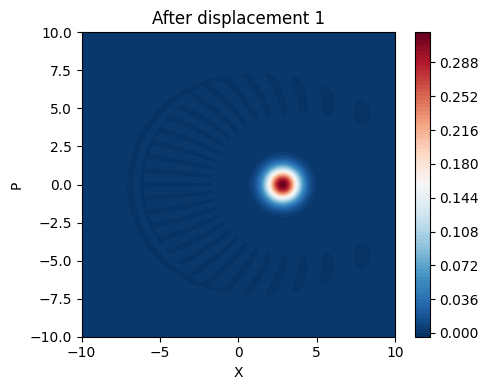


After parity measurement
P(even) = 0.5002
P(odd)  = 0.4998
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.294525


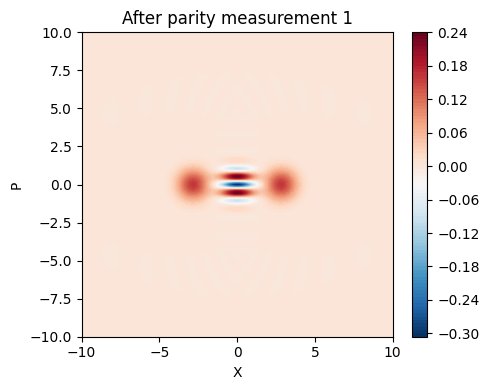

Measurement 2

After displacement
Wigner negativity = 0.329860


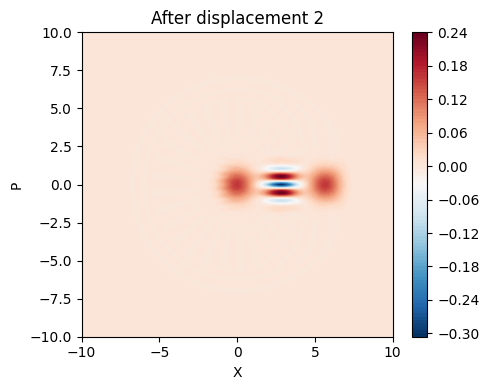


After parity measurement
P(even) = 0.7482
P(odd)  = 0.2518
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.403918


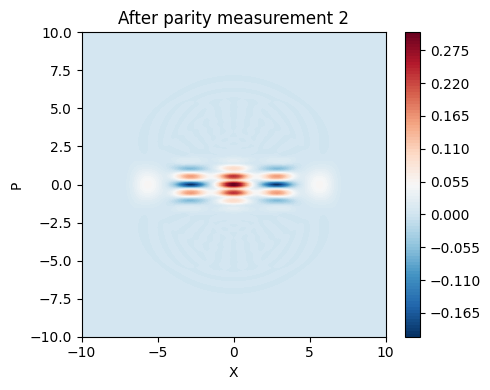

Measurement 3

After displacement
Wigner negativity = 0.641022


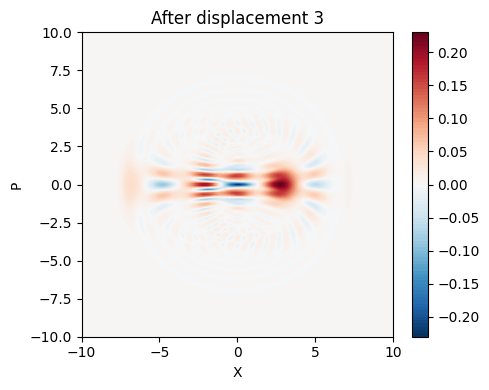


After parity measurement
P(even) = 0.1167
P(odd)  = 0.8833
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.681893


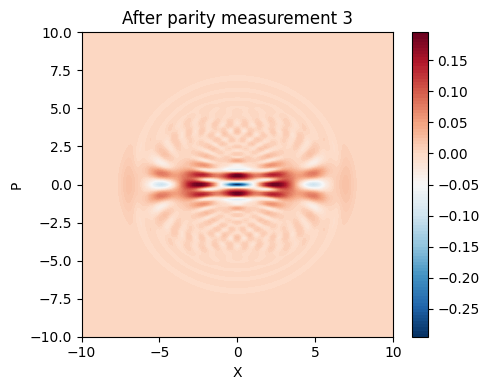

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 2.0
n_measurements = 3


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2




def displacement(state, alpha):

    D = qt.displace(N, alpha)

    return D * state


def parity_measurement(state):

    p_even = np.real(qt.expect(P_even, state))
    p_odd  = np.real(qt.expect(P_odd, state))

    if np.random.rand() < p_even:

        state = (P_even*state).unit()
        outcome = "EVEN (+1)"

    else:

        state = (P_odd*state).unit()
        outcome = "ODD (-1)"

    return state, outcome, p_even, p_odd


def wigner_negativity(state, x):

    W = qt.wigner(state, x, x)

    dx = x[1]-x[0]

    integral = np.sum(np.abs(W))*dx*dx
    negativity = max(0, 0.5*(integral-1))

    return negativity, W


def plot_wigner(W, x, title):

    plt.figure(figsize=(5,4))

    plt.contourf(x, x, W, 100, cmap="RdBu_r")

    plt.xlabel("X")
    plt.ylabel("P")
    plt.title(title)

    plt.colorbar()

    plt.tight_layout()
    plt.show()


#grid and initia state
x = np.linspace(-10,10,200)
psi = qt.basis(N,0)

print("\nInitial vacuum state\n")



for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")


    # Displacement


    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )


    # Parity measurement


    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

$\alpha$ = 0.5


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


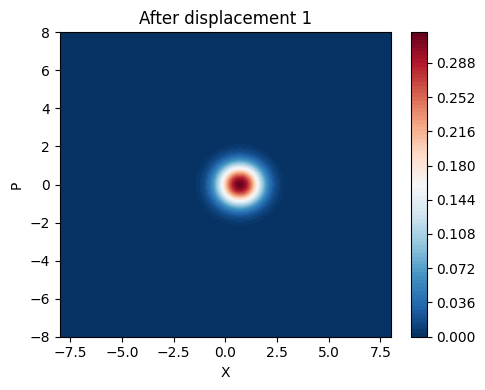


After parity measurement
P(even) = 0.8033
P(odd)  = 0.1967
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.001365


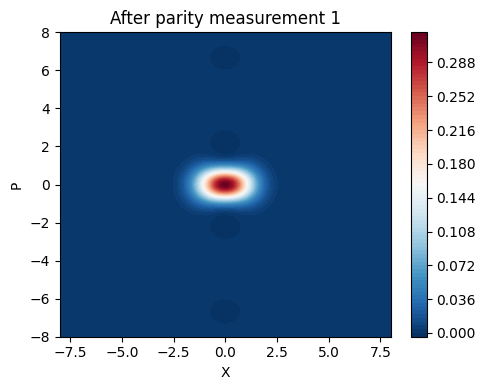

Measurement 2

After displacement
Wigner negativity = 0.001366


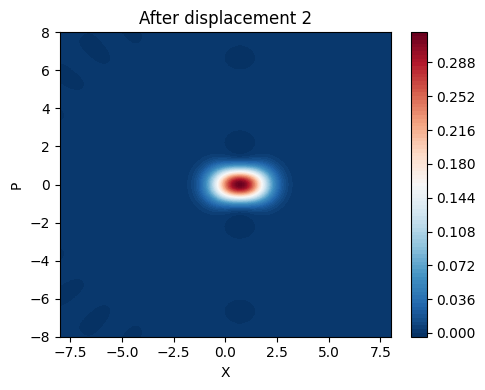


After parity measurement
P(even) = 0.8654
P(odd)  = 0.1346
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.001127


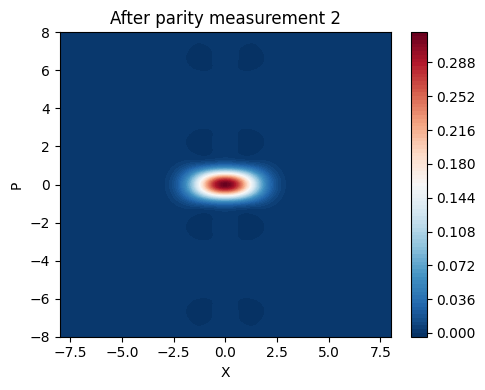

Measurement 3

After displacement
Wigner negativity = 0.001128


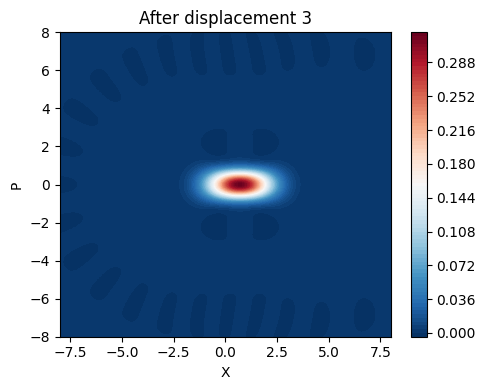


After parity measurement
P(even) = 0.8955
P(odd)  = 0.1045
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.000927


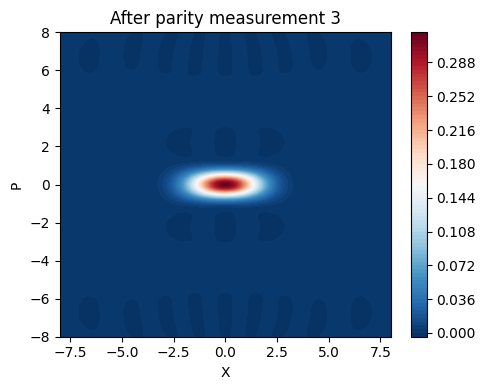

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 0.5
n_measurements = 3


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2




def displacement(state, alpha):

    D = qt.displace(N, alpha)

    return D * state


def parity_measurement(state):

    p_even = np.real(qt.expect(P_even, state))
    p_odd  = np.real(qt.expect(P_odd, state))

    if np.random.rand() < p_even:

        state = (P_even*state).unit()
        outcome = "EVEN (+1)"

    else:

        state = (P_odd*state).unit()
        outcome = "ODD (-1)"

    return state, outcome, p_even, p_odd


def wigner_negativity(state, x):

    W = qt.wigner(state, x, x)

    dx = x[1]-x[0]

    integral = np.sum(np.abs(W))*dx*dx
    negativity = max(0, 0.5*(integral-1))

    return negativity, W


def plot_wigner(W, x, title):

    plt.figure(figsize=(5,4))

    plt.contourf(x, x, W, 100, cmap="RdBu_r")

    plt.xlabel("X")
    plt.ylabel("P")
    plt.title(title)

    plt.colorbar()

    plt.tight_layout()
    plt.show()



x = np.linspace(-8,8,200)

psi = qt.basis(N,0)

print("\nInitial vacuum state\n")

for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )



    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

$\alpha$ = 1


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


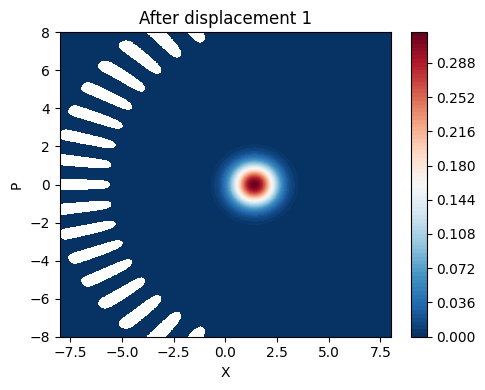


After parity measurement
P(even) = 0.5677
P(odd)  = 0.4323
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.103982


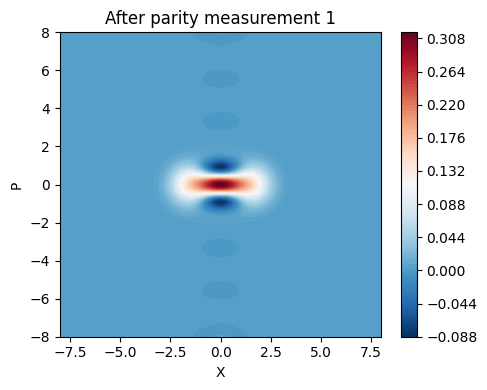

Measurement 2

After displacement
Wigner negativity = 0.103975


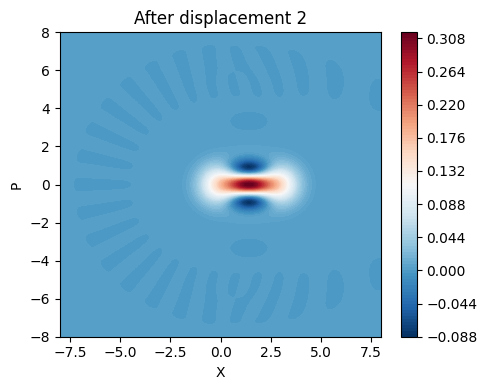


After parity measurement
P(even) = 0.7799
P(odd)  = 0.2201
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.123191


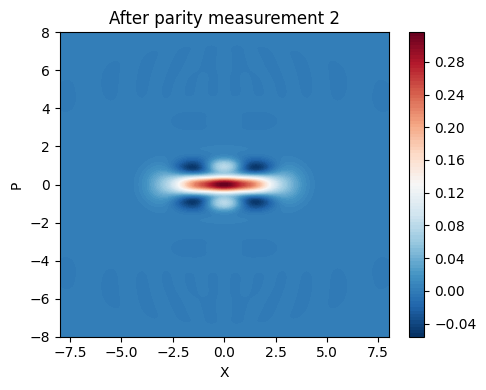

Measurement 3

After displacement
Wigner negativity = 0.123380


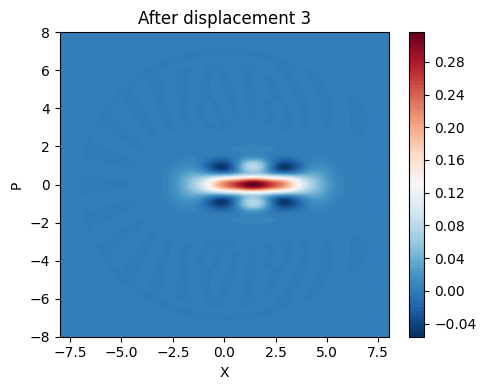


After parity measurement
P(even) = 0.8493
P(odd)  = 0.1507
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.128257


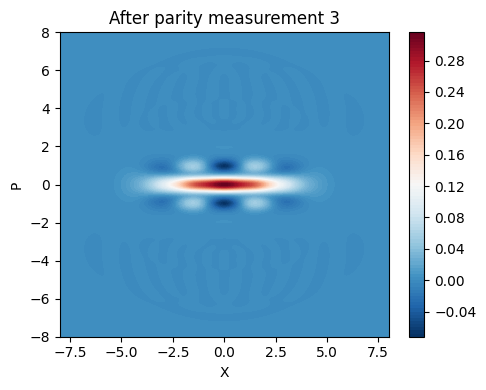

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 1
n_measurements = 3


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2




x = np.linspace(-8,8,200)

psi = qt.basis(N,0)

print("\nInitial vacuum state\n")



for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )


    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

$\alpha$ = 1.2


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


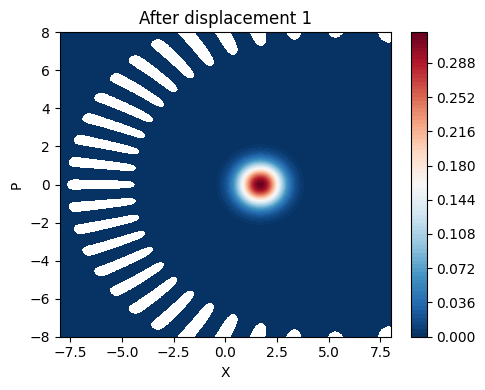


After parity measurement
P(even) = 0.5281
P(odd)  = 0.4719
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.169586


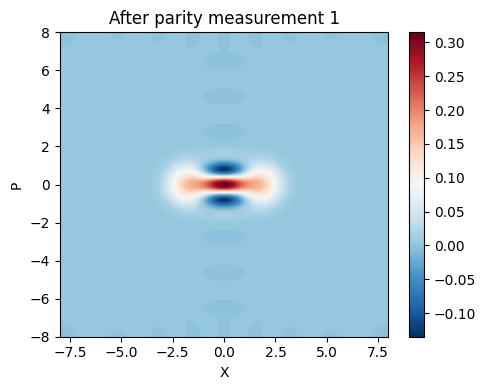

Measurement 2

After displacement
Wigner negativity = 0.169598


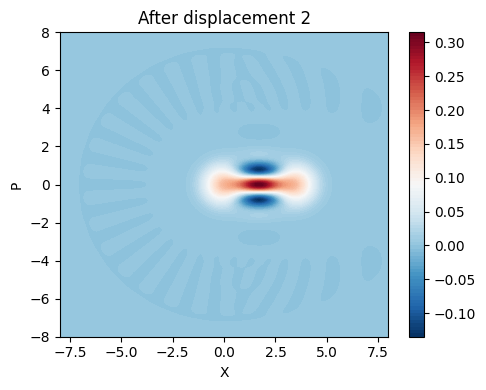


After parity measurement
P(even) = 0.7633
P(odd)  = 0.2367
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.212223


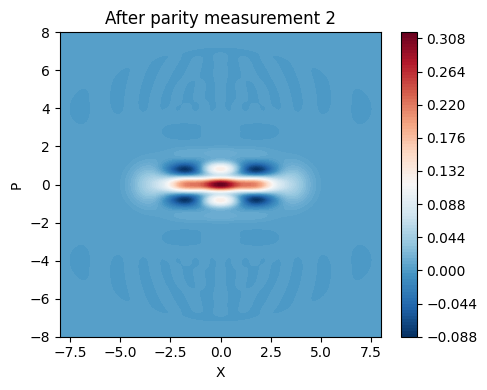

Measurement 3

After displacement
Wigner negativity = 0.214924


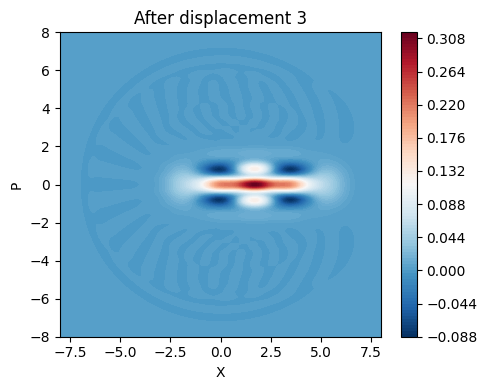


After parity measurement
P(even) = 0.8406
P(odd)  = 0.1594
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.227927


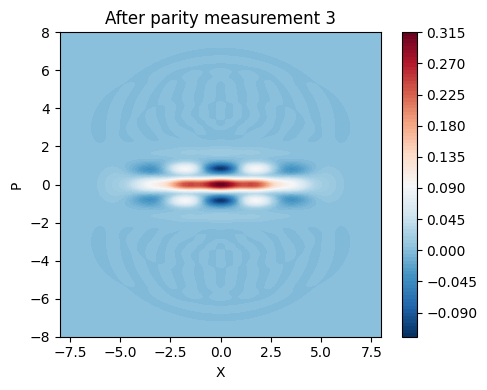

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 1.2
n_measurements = 3


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2



x = np.linspace(-8,8,200)

psi = qt.basis(N,0)

print("\nInitial vacuum state\n")



for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )

    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

**Physical and Mathematical Analysis of Parity Measurements in Quantum Trajectories**

 1. **The Role of Displacement ($\alpha$) on Parity Probabilities**

The application of the displacement operator $D(\alpha)$ onto the initial vacuum state $|0\rangle$ injects energy into the cavity, generating a **coherent state** $|\alpha\rangle$. A coherent state does not possess a fixed number of photons; instead, it represents a quantum superposition of Fock (photon-number) states $|n\rangle$ governed by a **Poisson distribution**:

$$P(n) = |\langle n | \alpha \rangle|^2 = \frac{|\alpha|^{2n} e^{-|\alpha|^2}}{n!}$$

-Small Displacement Regime ($\alpha = 0.5$)

When $\alpha$ is small, the mean photon number is very low and the Poisson distribution is strongly localized near the origin, meaning the vacuum state $|0\rangle$ dominates the superposition ($P(0) \approx 80\%$), while the single-photon state $|1\rangle$ carries most of the remaining weight ($P(1) \approx 20\%$).

This perfectly matches our simulation. Furthermore, sequentially measuring **EVEN** outcomes repeatedly filters out the odd components, trapping the state near the vacuum and causing $P_{\text{even}}$ to increase continuously across successive steps ($80.3\% \to 86.5\% \to 89.5\%$).

-Large Displacement Regime ($\alpha = 2.0$)

As $\alpha$ increases beyond $1.0$, the components of the state separate in phase space. For $\alpha = 2.0$, the mean photon number shifts to $ \tilde{n} = 4$, and the individual probabilities of all even Fock states ($|0\rangle, |2\rangle, |4\rangle, \dots$) and all odd Fock states ($|1\rangle, |3\rangle, |5\rangle, \dots$) balance each other out almost perfectly. As the exponential overlap term $e^{-2|\alpha|^2} \to 0$, the parity measurement probabilities collapse into an unbiased **50/50 split** ($P \approx 0.5$).



2. **Complexity of Subsequent Measurements**

While the first measurement always projects a coherent state into a standard **Schrödinger cat state** (either an even cat $|\alpha\rangle + |-\alpha\rangle$ or an odd cat $|\alpha\rangle - |-\alpha\rangle$), the subsequent steps grow highly complex.Depending on the value of $\alpha$, the components can constructively or destructively interfere, or even return to the origin. Consequently, the measurement probabilities at steps $k=2$ and $k=3$ no longer follow simple 50/50 rules; instead, they become heavily governed by whether previous outcomes were even or odd.


3. **Example of an Analytical Mathematical Derivation for the $\alpha = 2.0$ Trajectory**



We begin at the vacuum state $|\psi_0\rangle = |0\rangle$. Applying the first displacement yields a coherent state $|\alpha\rangle$. As shown previously, for $\alpha = 2.0$, $P_{\text{even}} \approx P_{\text{odd}} \approx 0.5$.

If our simulation registered an **EVEN (+1)** outcome, the state is projected via $P_{\text{even}}$, collapsing into a normalized **Even Schrödinger Cat State**:


$$|\psi_1\rangle\approx \frac{1}{\sqrt{2}} (|\alpha\rangle + |-\alpha\rangle)$$


When we apply the second displacement operator $D(\alpha)$ to our even cat state $|\psi_1\rangle$:


$$|\psi_{\text{disp2}}\rangle = D(\alpha)|\psi_1\rangle = \frac{1}{\sqrt{2}} \left( D(\alpha)|\alpha\rangle + D(\alpha)|-\alpha\rangle \right)$$

Using the composition rule for displacement operators (and noting that $\alpha$ is real, $\text{Im}(\alpha \cdot (-\alpha)^*) = 0$), we have $D(\alpha)D(\alpha) = D(2\alpha)$ and $D(\alpha)D(-\alpha) = D(0) = I$. Therefore, the state becomes:


$$|\psi_{\text{disp2}}\rangle = \frac{1}{\sqrt{2}} (|2\alpha\rangle + |0\rangle)$$

This tells us that **one half of the cat has been pushed far away, while the other half has returned to the vacuum $|0\rangle$**.

When calculating the probability of measuring even parity for this state:

* The vacuum component $|0\rangle$ is purely even ($P_{\text{even}} = 1$).
* The far-away coherent state $|4.0\rangle$ splits evenly ($P_{\text{even}} = 0.5$).
* Averaging both components yields $P_{\text{even}} = \frac{1}{2}(1) + \frac{1}{2}(0.5) = 0.75$. (**$74.84\%$** probability observed in the simulation).

If our simulation then registered an **ODD (-1)** outcome. The odd projector $P_{\text{odd}}$ completely obliterates the even vacuum component $|0\rangle$, and extracts the odd component of $|2\alpha\rangle$:


$$|\psi_2\rangle = \frac{1}{\sqrt{2}} (|2\alpha\rangle - |-2\alpha\rangle)$$


The system collapses into an **Odd Schrödinger Cat State** centered at $\pm 2\alpha$.


For the final step, we apply the third displacement $D(\alpha)$ to the odd cat state $|\psi_2\rangle$:


$$|\psi_{\text{disp3}}\rangle = D(\alpha)|\psi_2\rangle = \frac{1}{\sqrt{2}} \left( D(\alpha)|2\alpha\rangle - D(\alpha)|-2\alpha\rangle \right) = \frac{1}{\sqrt{2}} (|3\alpha\rangle - |-\alpha\rangle)$$



### Interpretation of the parity probabilities (average over evolutions)

The ensemble average reveals that, despite the stochastic nature of each individual quantum trajectory, the parity probabilities converge towards well-defined deterministic values. This behavior originates from the structure of the parity projectors and the geometry of the displaced states in phase space.

For the **third measurement**, the quantum state has undergone two projective collapses and therefore differs from one trajectory to another. Individual trajectories exhibit different parity probabilities depending on their measurement history. However, when averaged over many trajectories, the positive and negative contributions compensate each other. For sufficiently large displacements, the coherent components become well separated in phase space, their mutual interference becomes negligible, and the ensemble average approaches again the unbiased limit
$
P_{\rm even}\approx\frac12.
$


Running 300 trajectories for 40 different values of alpha...
Simulation finished! Generating plot...


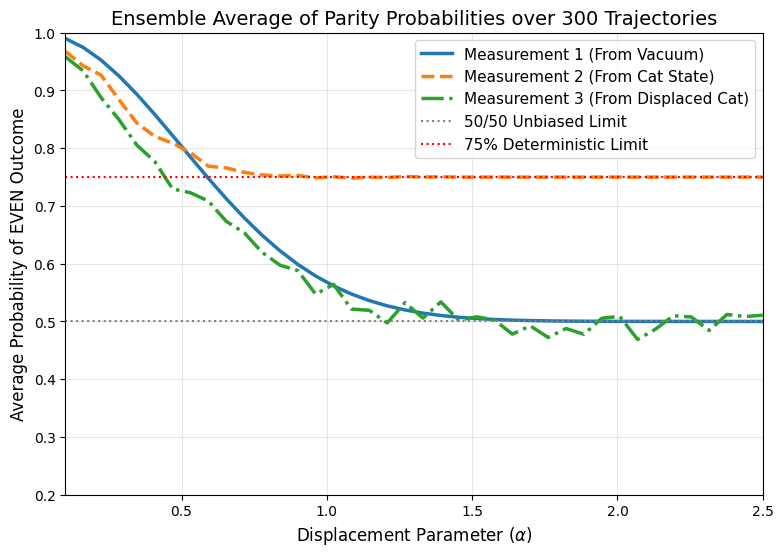

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

N = 80
n_measurements = 3
n_trajectories = 300  # number of trayectories

I = qt.qeye(N)
# Paruty operator
parity = sum((-1)**n * qt.basis(N,n) * qt.basis(N,n).dag() for n in range(N))

# projectors
P_even = (I + parity)/2
P_odd  = (I - parity)/2

def displacement(state, alpha):
    return qt.displace(N, alpha) * state

def parity_measurement(state):
    p_even = np.real(qt.expect(P_even, state))
    p_even = np.clip(p_even, 0.0, 1.0) # numeric estability


    if np.random.rand() < p_even:
        state = (P_even * state).unit()
    else:
        state = (P_odd * state).unit()
    return state, p_even


alpha_vals = np.linspace(0.1, 2.5, 40)


avg_p_even_m1 = []
avg_p_even_m2 = []
avg_p_even_m3 = []

print(f"Running {n_trajectories} trajectories for {len(alpha_vals)} different values of alpha...")

for alpha in alpha_vals:
    p_m1_accum = 0
    p_m2_accum = 0
    p_m3_accum = 0

    for traj in range(n_trajectories):
        # vacuum state
        psi = qt.basis(N, 0)

        # --- Ciclo 1 ---
        psi = displacement(psi, alpha)
        psi, pe1 = parity_measurement(psi)
        p_m1_accum += pe1

        # --- Ciclo 2 ---
        psi = displacement(psi, alpha)
        psi, pe2 = parity_measurement(psi)
        p_m2_accum += pe2

        # --- Ciclo 3 ---
        psi = displacement(psi, alpha)
        psi, pe3 = parity_measurement(psi)
        p_m3_accum += pe3

    # Calcular y almacenar el promedio de este valor de alpha
    avg_p_even_m1.append(p_m1_accum / n_trajectories)
    avg_p_even_m2.append(p_m2_accum / n_trajectories)
    avg_p_even_m3.append(p_m3_accum / n_trajectories)

print("Simulation finished! Generating plot...")


plt.figure(figsize=(9, 6))
plt.plot(alpha_vals, avg_p_even_m1, '-', label='Measurement 1 (From Vacuum)', lw=2.5)
plt.plot(alpha_vals, avg_p_even_m2, '--', label='Measurement 2 (From Cat State)', lw=2.5)
plt.plot(alpha_vals, avg_p_even_m3, '-.', label='Measurement 3 (From Displaced Cat)', lw=2.5)

# Líneas de guía teóricas para la discusión
plt.axhline(0.5, color='gray', linestyle=':', label='50/50 Unbiased Limit')
plt.axhline(0.75, color='red', linestyle=':', label='75% Deterministic Limit')

plt.xlabel(r'Displacement Parameter ($\alpha$)', fontsize=12)
plt.ylabel('Average Probability of EVEN Outcome', fontsize=12)
plt.title(f'Ensemble Average of Parity Probabilities over {n_trajectories} Trajectories', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.xlim(0.1, 2.5)
plt.ylim(0.2, 1.0)
plt.show()

### Multiples measurements


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


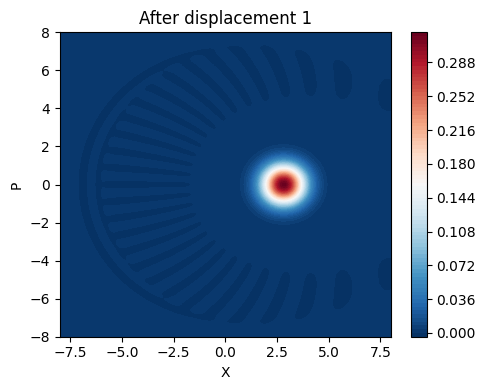


After parity measurement
P(even) = 0.5002
P(odd)  = 0.4998
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.292074


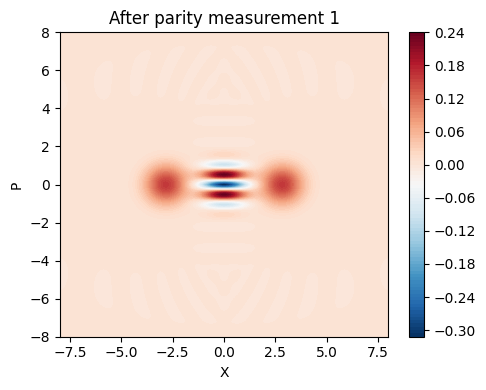

Measurement 2

After displacement
Wigner negativity = 0.327264


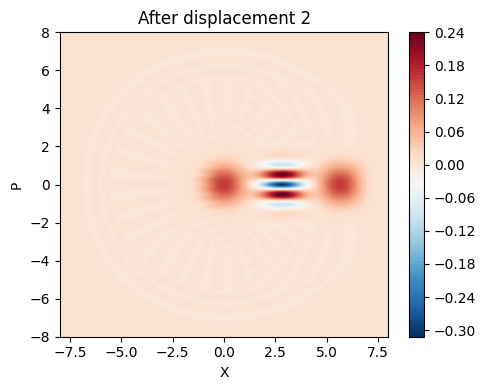


After parity measurement
P(even) = 0.7482
P(odd)  = 0.2518
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.400088


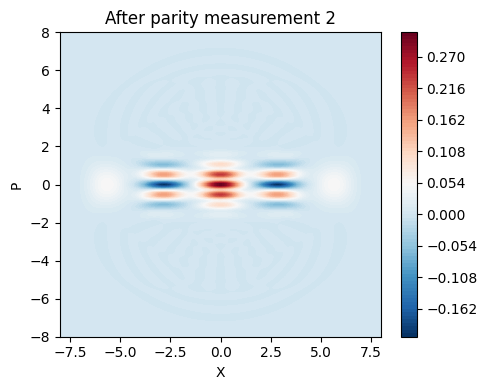

Measurement 3

After displacement
Wigner negativity = 0.642505


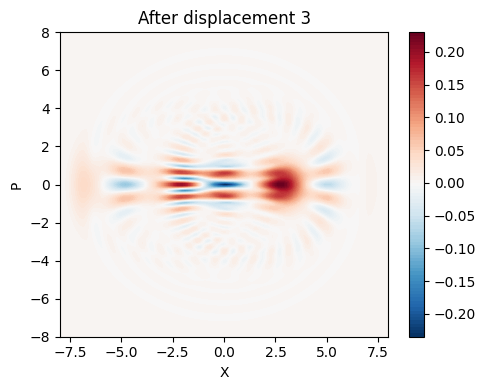


After parity measurement
P(even) = 0.1167
P(odd)  = 0.8833
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.681205


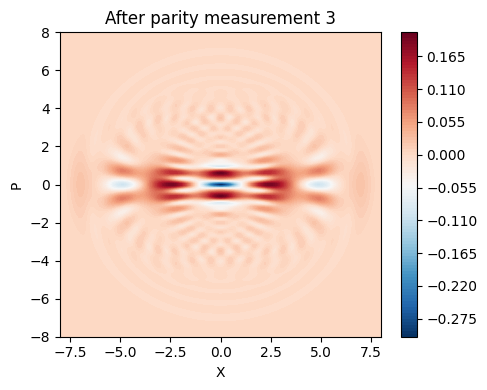

Measurement 4

After displacement
Wigner negativity = 0.430600


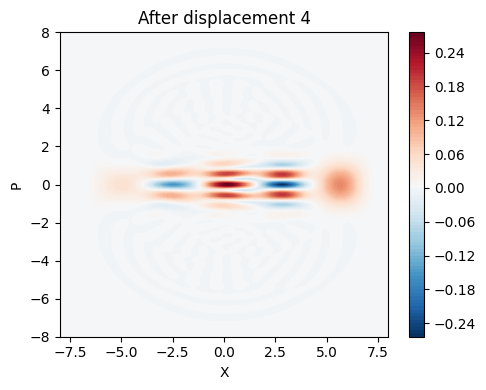


After parity measurement
P(even) = 0.9394
P(odd)  = 0.0606
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.426012


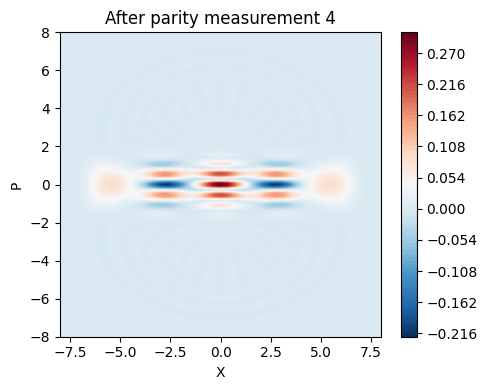

Measurement 5

After displacement
Wigner negativity = 0.783018


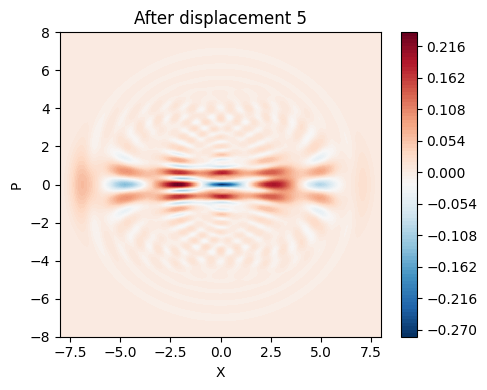


After parity measurement
P(even) = 0.0386
P(odd)  = 0.9614
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.791405


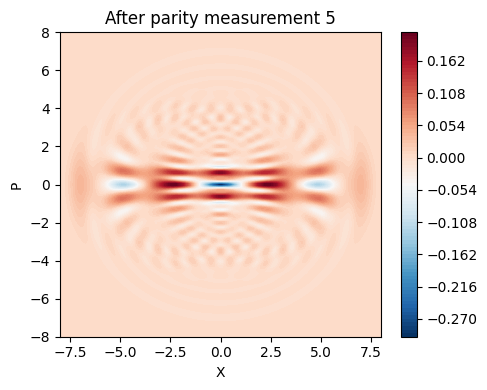

Measurement 6

After displacement
Wigner negativity = 0.439634


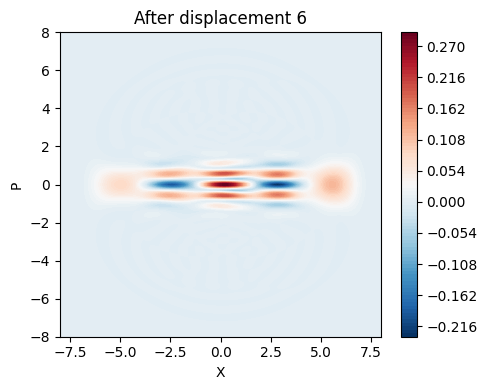


After parity measurement
P(even) = 0.9704
P(odd)  = 0.0296
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.432774


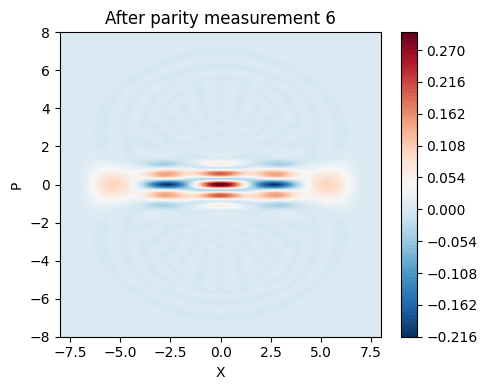

Measurement 7

After displacement
Wigner negativity = 0.812620


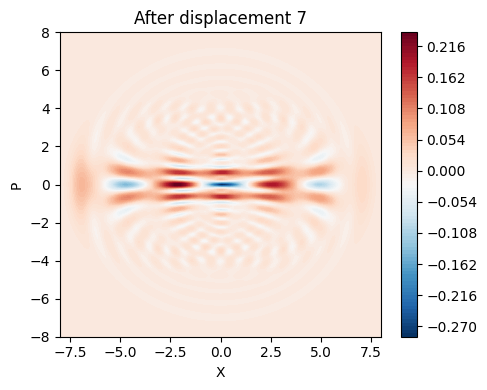


After parity measurement
P(even) = 0.0254
P(odd)  = 0.9746
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.818592


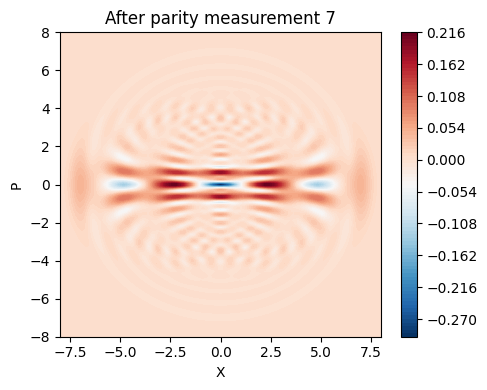

Measurement 8

After displacement
Wigner negativity = 0.439997


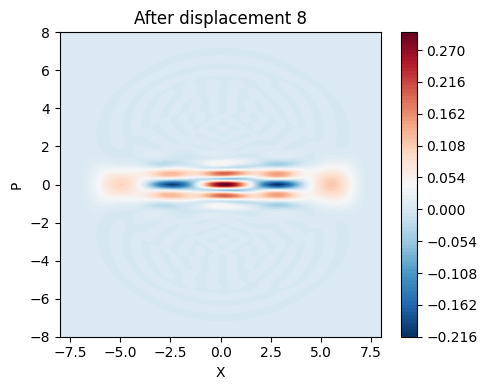


After parity measurement
P(even) = 0.9768
P(odd)  = 0.0232
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.430667


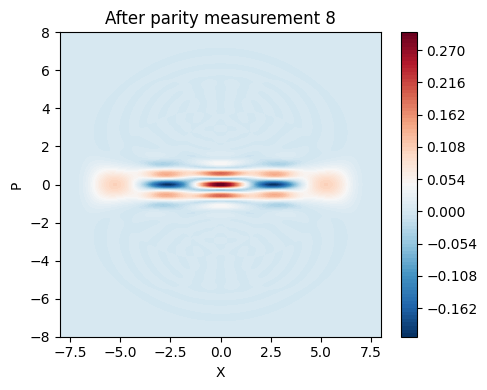

Measurement 9

After displacement
Wigner negativity = 0.822662


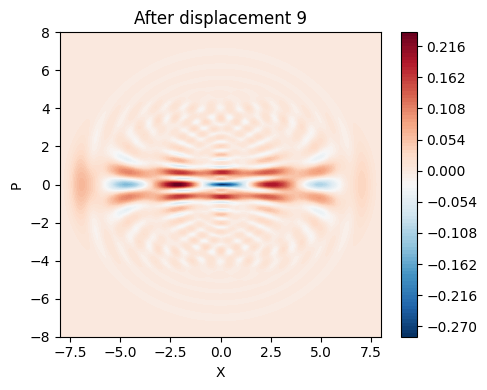


After parity measurement
P(even) = 0.0219
P(odd)  = 0.9781
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.829317


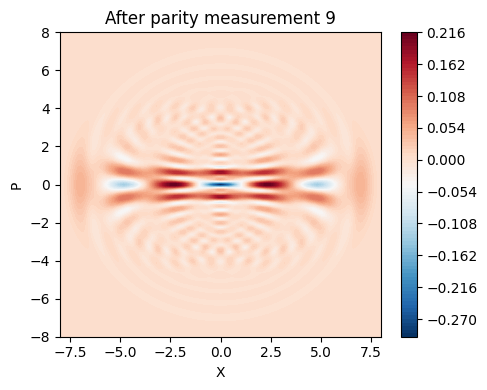

Measurement 10

After displacement
Wigner negativity = 0.439722


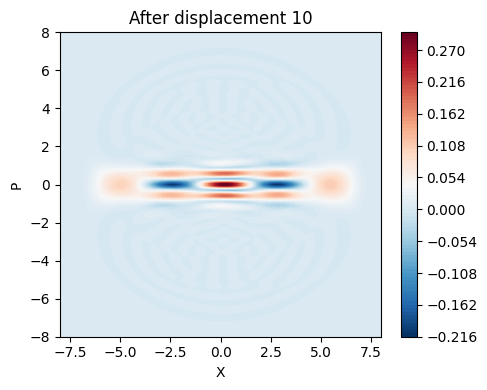


After parity measurement
P(even) = 0.9790
P(odd)  = 0.0210
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.426917


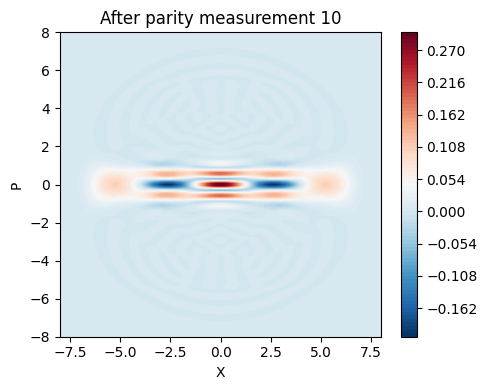

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 2.0
n_measurements = 10


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2



x = np.linspace(-8,8,200)

psi = qt.basis(N,0)

print("\nInitial vacuum state\n")

for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )



    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

### $\alpha$ = 1+2j


Initial vacuum state

Measurement 1

After displacement
Wigner negativity = 0.000000


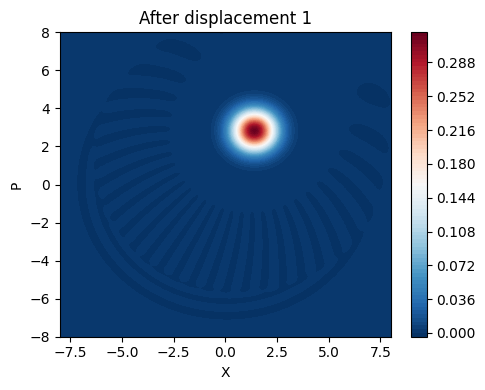


After parity measurement
P(even) = 0.5000
P(odd)  = 0.5000
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.304922


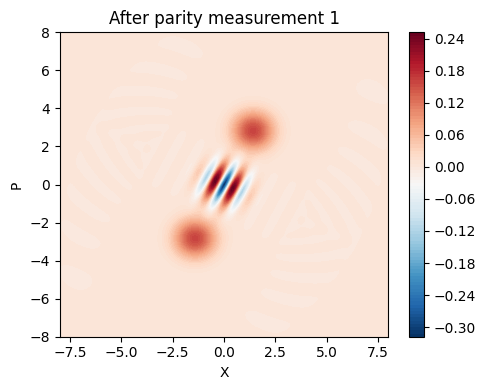

Measurement 2

After displacement
Wigner negativity = 0.465294


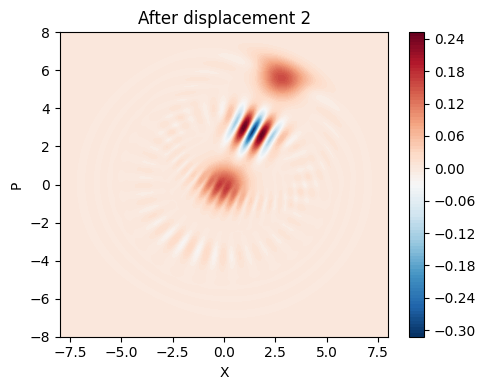


After parity measurement
P(even) = 0.7238
P(odd)  = 0.2762
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.439245


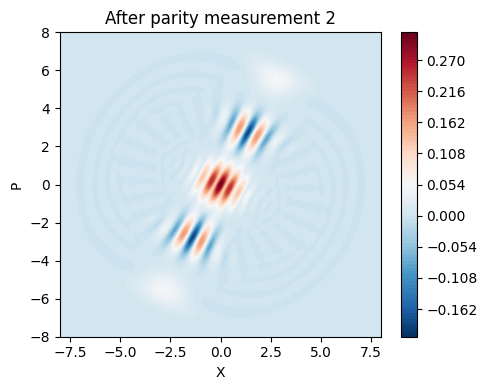

Measurement 3

After displacement
Wigner negativity = 0.472333


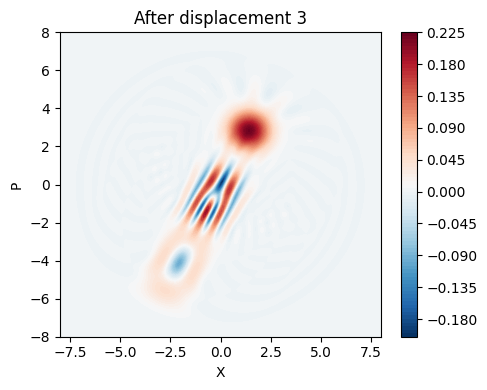


After parity measurement
P(even) = 0.1851
P(odd)  = 0.8149
Outcome = ODD (-1)
<Parity> = -1.0000
Wigner negativity = 0.522315


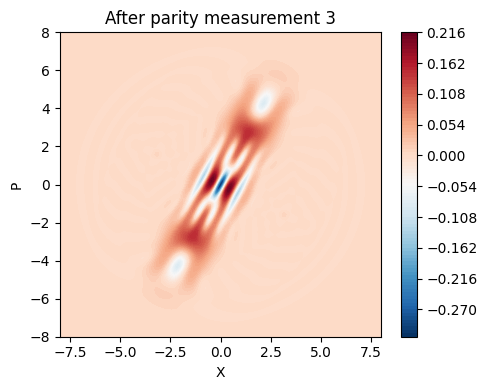

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30
alpha = 1+2j #(|\alpha|^2 = 1^2 + 2^2 = 5)
n_measurements = 3


a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

# Projectors

P_even = (I + parity)/2
P_odd  = (I - parity)/2



x = np.linspace(-8,8,200)

psi = qt.basis(N,0)

print("\nInitial vacuum state\n")



for k in range(n_measurements):

    print("="*60)
    print(f"Measurement {k+1}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1}"
    )



    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print(f"\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")

    print(f"<Parity> = {parity_expectation:.4f}")

    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1}"
    )

### Differents values of $\alpha$


Initial vacuum state

Measurement 1
Displacement amplitude α = 0.5

After displacement
Wigner negativity = 0.000000


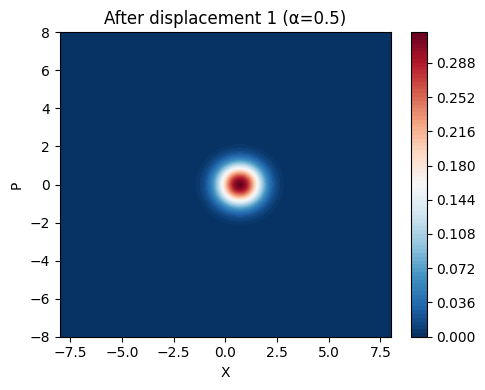


After parity measurement
P(even) = 0.8033
P(odd)  = 0.1967
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.001365


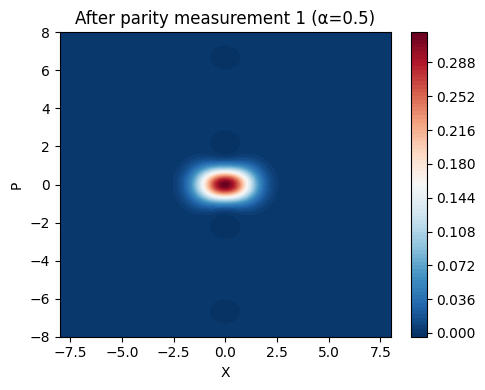

Measurement 2
Displacement amplitude α = 1.0

After displacement
Wigner negativity = 0.001367


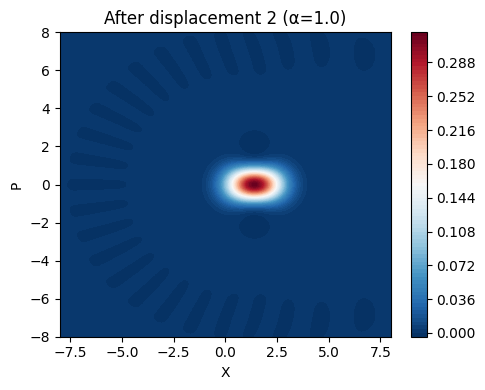


After parity measurement
P(even) = 0.6382
P(odd)  = 0.3618
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.032977


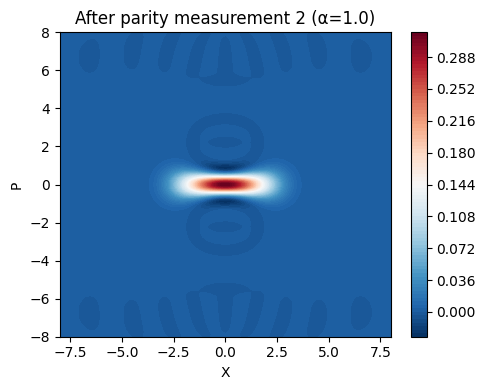

Measurement 3
Displacement amplitude α = 2.0

After displacement
Wigner negativity = 0.034815


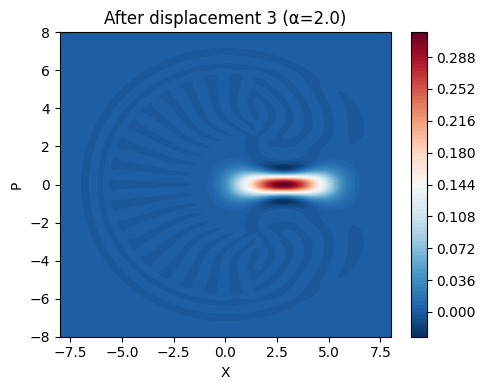


After parity measurement
P(even) = 0.5556
P(odd)  = 0.4444
Outcome = EVEN (+1)
<Parity> = 1.0000
Wigner negativity = 0.113854


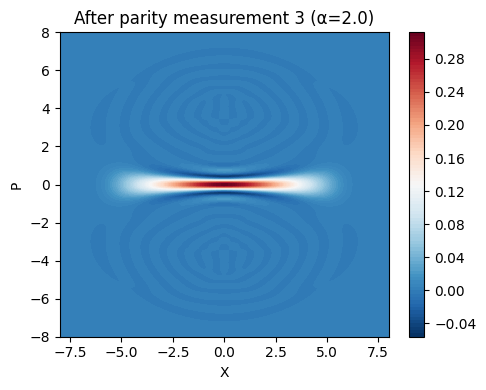


Protocol finished.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 30                           # Hilbert space truncation
alphas = [0.5, 1.0, 2.0]
n_measurements = len(alphas)



a = qt.destroy(N)
I = qt.qeye(N)

# Photon-number parity operator
parity = sum(
    (-1)**n * qt.basis(N, n) * qt.basis(N, n).dag()
    for n in range(N)
)

# Parity projectors
P_even = (I + parity) / 2
P_odd  = (I - parity) / 2



def displacement(state, alpha):
    """Apply the displacement operator D(alpha)."""
    D = qt.displace(N, alpha)
    return D * state


def parity_measurement(state):
    """Perform a projective parity measurement."""

    p_even = np.real(qt.expect(P_even, state))
    p_odd  = np.real(qt.expect(P_odd, state))

    if np.random.rand() < p_even:
        state = (P_even * state).unit()
        outcome = "EVEN (+1)"
    else:
        state = (P_odd * state).unit()
        outcome = "ODD (-1)"

    return state, outcome, p_even, p_odd


def wigner_negativity(state, x):
    """Compute Wigner function and its negativity."""

    W = qt.wigner(state, x, x)

    dx = x[1] - x[0]

    integral = np.sum(np.abs(W)) * dx * dx
    negativity = max(0, 0.5 * (integral - 1))

    return negativity, W


def plot_wigner(W, x, title):

    plt.figure(figsize=(5,4))

    plt.contourf(x, x, W, 100, cmap="RdBu_r")

    plt.xlabel("X")
    plt.ylabel("P")
    plt.title(title)

    plt.colorbar()

    plt.tight_layout()
    plt.show()



x = np.linspace(-8, 8, 200)


psi = qt.basis(N, 0)

print("\nInitial vacuum state\n")


for k, alpha in enumerate(alphas):

    print("=" * 60)
    print(f"Measurement {k+1}")
    print(f"Displacement amplitude α = {alpha}")



    psi = displacement(psi, alpha)

    negativity, W = wigner_negativity(psi, x)

    print("\nAfter displacement")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After displacement {k+1} (α={alpha})"
    )

    psi, outcome, pe, po = parity_measurement(psi)

    parity_expectation = np.real(qt.expect(parity, psi))

    negativity, W = wigner_negativity(psi, x)

    print("\nAfter parity measurement")

    print(f"P(even) = {pe:.4f}")
    print(f"P(odd)  = {po:.4f}")
    print(f"Outcome = {outcome}")
    print(f"<Parity> = {parity_expectation:.4f}")
    print(f"Wigner negativity = {negativity:.6f}")

    plot_wigner(
        W,
        x,
        f"After parity measurement {k+1} (α={alpha})"
    )

print("\nProtocol finished.")

### **Average displacement of the state in phase space**


To understand how the state moves in phase space during the repeated displacement–parity protocol, it is useful to compute the expectation value of the annihilation operator,

$$
\langle a \rangle = \langle \psi | a | \psi \rangle.
$$

This quantity determines the center of the Wigner function. Since the field quadratures are defined as

$$
\hat{x}=\frac{a+a^\dagger}{\sqrt{2}}, \qquad
\hat{p}=\frac{a-a^\dagger}{i\sqrt{2}},
$$

their expectation values are

$$
\boxed{
\langle x\rangle=\sqrt{2}\,\mathrm{Re}\!\left(\langle a\rangle\right),
\qquad
\langle p\rangle=\sqrt{2}\,\mathrm{Im}\!\left(\langle a\rangle\right).
}
$$

Therefore, measuring $\langle a\rangle$ is equivalent to tracking the position of the Wigner function in phase space.


The displacement operator is

$$
D(\alpha)=e^{\alpha a^\dagger-\alpha^*a},
$$

which satisfies the identity

$$
D^\dagger(\alpha)\,a\,D(\alpha)=a+\alpha.
$$

Hence, after applying a displacement,

$$
|\psi'\rangle=D(\alpha)|\psi\rangle,
$$

the expectation value becomes

$$
\begin{aligned}
\langle a\rangle'
&=
\langle\psi|D^\dagger(\alpha)aD(\alpha)|\psi\rangle \\
&=
\langle\psi|(a+\alpha)|\psi\rangle \\
&=
\boxed{\langle a\rangle+\alpha.}
\end{aligned}
$$

This result shows that every displacement translates the center of the state by exactly the complex number $\alpha$.




The action of the parity measurement can be understood directly from the algebra of the parity operator. The photon-number parity operator is defined as

$$
\Pi = (-1)^{a^\dagger a},
$$

whose eigenvalues are

$$
\Pi|\psi_\pm\rangle=\pm|\psi_\pm\rangle,
$$

corresponding to states with definite even or odd photon-number parity.

The annihilation operator changes the parity of a Fock state:
$$
a|n\rangle=\sqrt{n}\,|n-1\rangle,
$$
so that
- an even Fock state is mapped onto an odd one,
- an odd Fock state is mapped onto an even one.

Mathematically, this is expressed through the anticommutation relation $$\Pi a \Pi = -a,
$$

Now consider a state that has just been projected onto a parity eigenstate. Its expectation value of the annihilation operator is

$$
\langle a\rangle
=
\langle\psi|a|\psi\rangle.
$$

Inserting the identity operator in the form $\Pi^2=I$,

$$
\langle a\rangle
=
\langle\psi|\Pi a\Pi|\psi\rangle.
$$

Using the anticommutation relation,

$$
\Pi a\Pi=-a,
$$

we obtain

$$
\langle a\rangle
=
-\langle\psi|a|\psi\rangle.
$$

The only quantity equal to its own negative is zero, therefore

$$
\boxed{
\langle a\rangle=0.
}
$$

Since the operator $a$ always changes the parity of a state, while the state itself possesses a definite parity after the measurement, the average transition amplitude between the state and itself must vanish. Consequently, every parity eigenstate has zero first moment.

Geometrically, the expectation value $\langle a\rangle$ determines the center of the Wigner function. Therefore, regardless of how far the displacement operation has translated the state, the parity projection always restores the center of the Wigner distribution to the origin of phase space.



For the simulations presented here the displacement parameter is purely real ($\alpha=2$), so

$$
\boxed{
\langle X\rangle=\sqrt{2}\,\alpha,
\qquad
\langle P\rangle=0,
}
$$

immediately after each displacement, whereas after every parity measurement

$$
\boxed{
\langle X\rangle=\langle P\rangle=0.
}
$$

The numerical results therefore exhibit an alternating evolution: the displacement shifts the center of the Wigner function by a fixed amount, while the parity measurement collapses the state into a parity eigenstate whose center is exactly reset to the origin. What changes from one cycle to the next is not the position of the center, but the internal structure of the quantum state, which becomes progressively more non-classical through the buildup of interference and higher-order Fock-state components.







The numerical simulations perfectly reproduce this analytical prediction. The ensemble-averaged trajectory repeatedly moves from the origin to $(\sqrt{2}\alpha,0)$ after each displacement and returns to the origin after every measurement, with only negligible numerical errors due to the finite Hilbert-space truncation.

An important conclusion follows from this result. Although the parity measurements dramatically modify the quantum state—transforming it into increasingly complex Schrödinger-cat superpositions with rich interference patterns—they never change its center in phase space. The displacement of the Wigner function is therefore **not** a useful observable to characterize the dynamics of the protocol, since it always follows the same trivial oscillation,

$$
0
\;\longrightarrow\;
\alpha
\;\longrightarrow\;
0
\;\longrightarrow\;
\alpha
\;\longrightarrow\;\cdots
$$

independently of how non-classical the state becomes. The relevant physics is instead encoded in higher-order quantities such as the average photon number, the photon-number distribution, and the Wigner negativity, which capture the increasing complexity of the generated quantum states.




Average displacement of the Wigner center

Measurement cycle 1

After displacement
<X> = 2.828427
<P> = 0.000000
<a> = (2.0000000000000124+0j)

After parity measurement
<X> = 0.000000
<P> = 0.000000
<a> = 0j
Measurement cycle 2

After displacement
<X> = 2.828427
<P> = 0.000000
<a> = (2.0000000000000124+0j)

After parity measurement
<X> = 0.000000
<P> = 0.000000
<a> = 0j
Measurement cycle 3

After displacement
<X> = 2.828427
<P> = 0.000000
<a> = (2.0000000000000124+0j)

After parity measurement
<X> = 0.000000
<P> = 0.000000
<a> = 0j
Measurement cycle 4

After displacement
<X> = 2.828427
<P> = 0.000000
<a> = (2.0000000000000124+0j)

After parity measurement
<X> = 0.000000
<P> = 0.000000
<a> = 0j
Measurement cycle 5

After displacement
<X> = 2.828423
<P> = 0.000000
<a> = (1.9999973409986096+0j)

After parity measurement
<X> = 0.000000
<P> = 0.000000
<a> = 0j


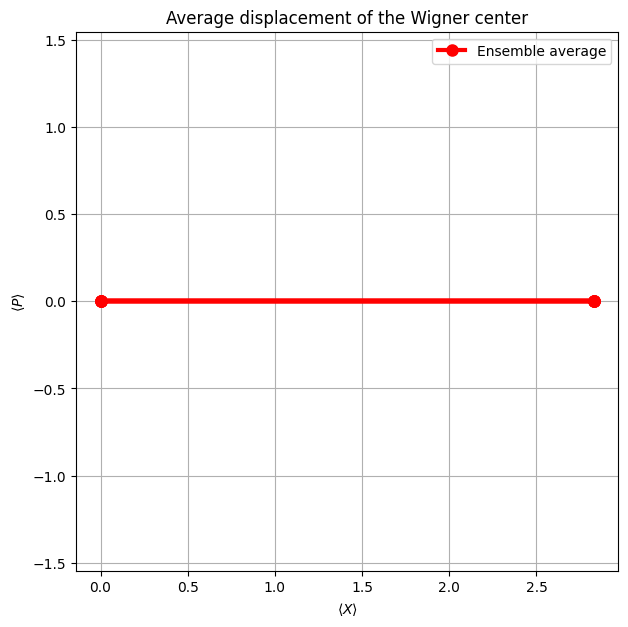

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

N = 150
alpha = 2.0

n_measurements = 5
n_trajectories = 500

x = np.linspace(-10,10,300)

a = qt.destroy(N)
I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


def displacement(state, alpha):
    return qt.displace(N, alpha) * state


def parity_measurement(state):

    pe = np.real(qt.expect(P_even, state))

    if np.random.rand() < pe:
        state = (P_even * state).unit()
    else:
        state = (P_odd * state).unit()

    return state



mean_x = np.zeros((n_trajectories, 2*n_measurements))
mean_p = np.zeros((n_trajectories, 2*n_measurements))

for traj in range(n_trajectories):

    psi = qt.basis(N,0)

    step = 0

    for k in range(n_measurements):

        psi = displacement(psi, alpha)

        alpha_exp = qt.expect(a, psi)

        mean_x[traj, step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj, step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1

        psi = parity_measurement(psi)

        alpha_exp = qt.expect(a, psi)

        mean_x[traj, step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj, step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1



avg_x = mean_x.mean(axis=0)
avg_p = mean_p.mean(axis=0)

print("\nAverage displacement of the Wigner center\n")

for k in range(n_measurements):

    disp = 2*k
    meas = 2*k + 1

    print("="*50)
    print(f"Measurement cycle {k+1}")

    print("\nAfter displacement")
    print(f"<X> = {avg_x[disp]:.6f}")
    print(f"<P> = {avg_p[disp]:.6f}")
    print(f"<a> = {(avg_x[disp] + 1j*avg_p[disp])/np.sqrt(2)}")

    print("\nAfter parity measurement")
    print(f"<X> = {avg_x[meas]:.6f}")
    print(f"<P> = {avg_p[meas]:.6f}")
    print(f"<a> = {(avg_x[meas] + 1j*avg_p[meas])/np.sqrt(2)}")




plt.figure(figsize=(7,7))

for i in range(n_trajectories):
    plt.plot(mean_x[i],
             mean_p[i],
             color='lightgray',
             alpha=0.05)

plt.plot(avg_x,
         avg_p,
         '-o',
         color='red',
         lw=3,
         markersize=8,
         label='Ensemble average')

plt.xlabel(r'$\langle X\rangle$')
plt.ylabel(r'$\langle P\rangle$')
plt.title("Average displacement of the Wigner center")

plt.grid(True)
plt.axis('equal')
plt.legend()

plt.show()

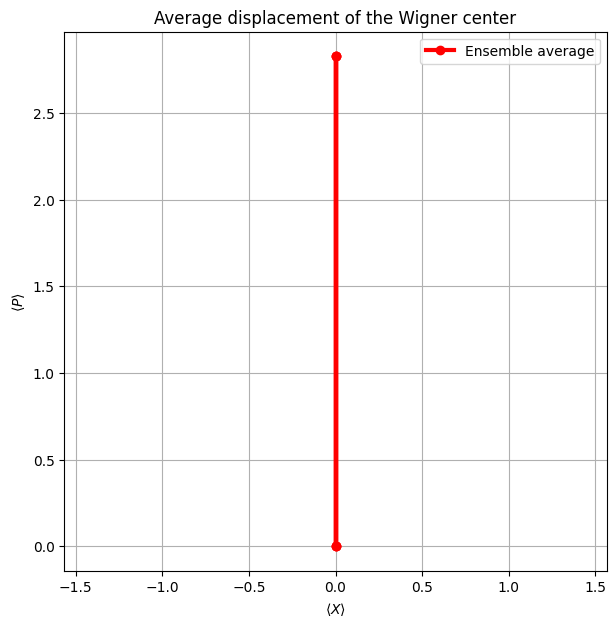

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 80
alpha = 2.0j

n_measurements = 3
n_trajectories = 500

x = np.linspace(-10,10,300)

a = qt.destroy(N)
I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


mean_x = np.zeros((n_trajectories,2*n_measurements))
mean_p = np.zeros((n_trajectories,2*n_measurements))


for traj in range(n_trajectories):

    psi = qt.basis(N,0)

    step = 0

    for k in range(n_measurements):

        # displacement
        psi = displacement(psi,alpha)

        alpha_exp = qt.expect(a,psi)

        mean_x[traj,step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj,step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1

        # parity measurement
        psi = parity_measurement(psi)

        alpha_exp = qt.expect(a,psi)

        mean_x[traj,step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj,step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1

avg_x = mean_x.mean(axis=0)
avg_p = mean_p.mean(axis=0)


plt.figure(figsize=(7,7))

for i in range(n_trajectories):
    plt.plot(mean_x[i],mean_p[i],
             color='lightgray',
             alpha=0.08)

plt.plot(avg_x,avg_p,
         '-o',
         color='red',
         lw=3,
         label='Ensemble average')

plt.xlabel(r'$\langle X\rangle$')
plt.ylabel(r'$\langle P\rangle$')

plt.title("Average displacement of the Wigner center")

plt.grid(True)
plt.axis('equal')
plt.legend()

plt.show()

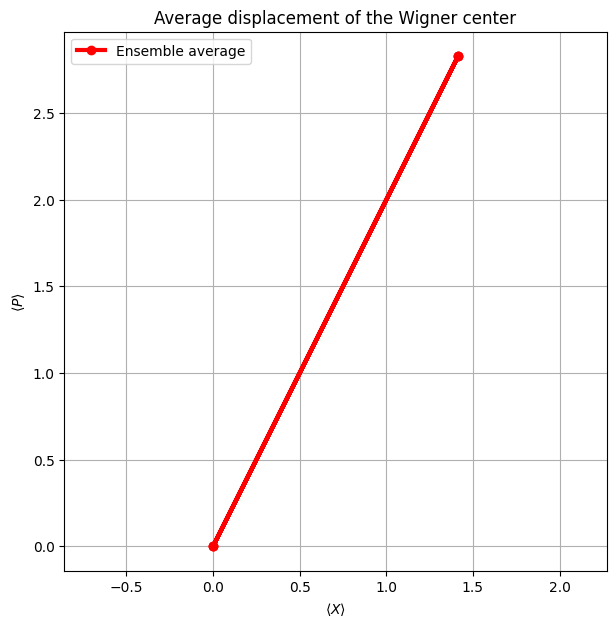

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt



N = 80
alpha = 1+2.0j

n_measurements = 3
n_trajectories = 500

x = np.linspace(-10,10,300)

a = qt.destroy(N)
I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I+parity)/2
P_odd  = (I-parity)/2


mean_x = np.zeros((n_trajectories,2*n_measurements))
mean_p = np.zeros((n_trajectories,2*n_measurements))


for traj in range(n_trajectories):

    psi = qt.basis(N,0)

    step = 0

    for k in range(n_measurements):

        # displacement
        psi = displacement(psi,alpha)

        alpha_exp = qt.expect(a,psi)

        mean_x[traj,step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj,step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1

        # parity measurement
        psi = parity_measurement(psi)

        alpha_exp = qt.expect(a,psi)

        mean_x[traj,step] = np.sqrt(2)*np.real(alpha_exp)
        mean_p[traj,step] = np.sqrt(2)*np.imag(alpha_exp)

        step += 1

avg_x = mean_x.mean(axis=0)
avg_p = mean_p.mean(axis=0)


plt.figure(figsize=(7,7))

for i in range(n_trajectories):
    plt.plot(mean_x[i],mean_p[i],
             color='lightgray',
             alpha=0.08)

plt.plot(avg_x,avg_p,
         '-o',
         color='red',
         lw=3,
         label='Ensemble average')

plt.xlabel(r'$\langle X\rangle$')
plt.ylabel(r'$\langle P\rangle$')

plt.title("Average displacement of the Wigner center")

plt.grid(True)
plt.axis('equal')
plt.legend()

plt.show()

To characterize how the protocol modifies the energy of the field, we computed the average photon number:

$$
\langle n\rangle=\langle a^\dagger a\rangle,
$$

after every displacement and parity measurement, averaging over a large ensemble of independent quantum trajectories.

Immediately after each displacement, the average photon number increases by a constant amount,

$$
\boxed{
\Delta\langle n\rangle=|\alpha|^2.
}
$$

Since

$$
D^\dagger(\alpha)\,a\,D(\alpha)=a+\alpha,
$$

we obtain

$$
\begin{aligned}
D^\dagger(\alpha)\,a^\dagger a\,D(\alpha)
&=(a^\dagger+\alpha^*)(a+\alpha)\\
&=a^\dagger a
+\alpha a^\dagger
+\alpha^*a
+|\alpha|^2.
\end{aligned}
$$

Taking the expectation value gives

$$
\langle n\rangle'
=
\langle n\rangle
+\alpha\langle a^\dagger\rangle
+\alpha^*\langle a\rangle
+|\alpha|^2.
$$

After every parity measurement the state is projected onto an eigenstate of the parity operator, for which

$$
\langle a\rangle=\langle a^\dagger\rangle=0.
$$

Consequently,

$$
\boxed{
\langle n\rangle'
=
\langle n\rangle
+
|\alpha|^2.
}
$$

For the simulations presented here, where $\alpha=2$, every displacement injects exactly

$$
|\alpha|^2=4
$$

photons on average, producing the sequence

$$
4,\;8,\;12,\;16,\;20,
$$

which is in excellent agreement with the numerical results.

Unlike the displacement operation, the parity measurement does not systematically modify the average energy of the field. This follows from the fact that the photon-number operator commutes with the parity operator,

$$
[a^\dagger a,\Pi]=0,
$$

meaning that both observables are compatible. The measurement only redistributes the state within either the even or odd Fock subspace, without creating or destroying photons on average.

The individual quantum trajectories, however, behave very differently. Each parity measurement randomly projects the system onto either the even- or odd-parity subspace, causing the photon number of a single realization to jump upward or downward depending on the measurement outcome. These stochastic jumps correspond to the quantum measurement back-action and are clearly visible as the gray trajectories in the figure.

When averaging over the ensemble of trajectories, these positive and negative fluctuations cancel statistically, producing the deterministic staircase followed by the red curve. The small deviations observed after each measurement originate from the finite number of Monte Carlo trajectories used in the simulation and decrease as the ensemble size increases.

Overall, the displacement operator continuously pumps energy into the cavity, while the parity measurement reshapes the quantum state without significantly modifying its average energy. Consequently, the average photon number grows linearly with the number of displacement operations, whereas the increasingly rich interference fringes and Wigner negativity arise solely from the redistribution of that energy among the even and odd sectors of the Fock basis rather than from an additional energy gain during the measurement process.


Average photon number

Measurement cycle 1

After displacement
<a†a> = 4.000000

After parity measurement
<a†a> = 3.999915
Measurement cycle 2

After displacement
<a†a> = 7.999915

After parity measurement
<a†a> = 7.957282
Measurement cycle 3

After displacement
<a†a> = 11.957282

After parity measurement
<a†a> = 12.089581
Measurement cycle 4

After displacement
<a†a> = 16.089581

After parity measurement
<a†a> = 16.032959
Measurement cycle 5

After displacement
<a†a> = 20.032959

After parity measurement
<a†a> = 19.884166


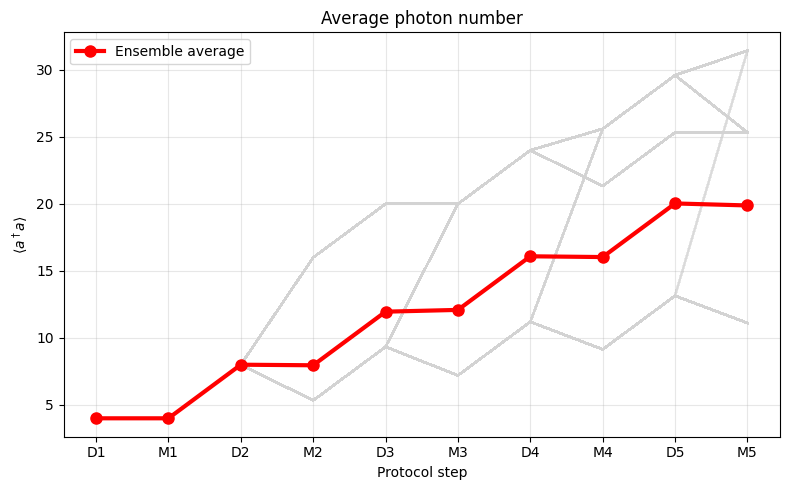

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt


N = 150
alpha = 2.0

n_measurements = 5
n_trajectories = 500


a = qt.destroy(N)
n_op = a.dag()*a

I = qt.qeye(N)

parity = sum(
    (-1)**n * qt.basis(N,n) * qt.basis(N,n).dag()
    for n in range(N)
)

P_even = (I + parity)/2
P_odd  = (I - parity)/2



def displacement(state, alpha):
    return qt.displace(N, alpha) * state


def parity_measurement(state):

    pe = np.real(qt.expect(P_even, state))

    if np.random.rand() < pe:
        state = (P_even * state).unit()
    else:
        state = (P_odd * state).unit()

    return state


mean_n = np.zeros((n_trajectories, 2*n_measurements))



for traj in range(n_trajectories):

    psi = qt.basis(N,0)

    step = 0

    for k in range(n_measurements):

        psi = displacement(psi, alpha)

        mean_n[traj, step] = qt.expect(n_op, psi)

        step += 1



        psi = parity_measurement(psi)

        mean_n[traj, step] = qt.expect(n_op, psi)

        step += 1



avg_n = mean_n.mean(axis=0)

print("\nAverage photon number\n")

for k in range(n_measurements):

    disp = 2*k
    meas = 2*k + 1

    print("="*50)
    print(f"Measurement cycle {k+1}")

    print(f"\nAfter displacement")
    print(f"<a†a> = {avg_n[disp]:.6f}")

    print(f"\nAfter parity measurement")
    print(f"<a†a> = {avg_n[meas]:.6f}")



steps = np.arange(2*n_measurements)

labels = []

for k in range(n_measurements):
    labels.append(f"D{k+1}")
    labels.append(f"M{k+1}")

plt.figure(figsize=(8,5))

for i in range(n_trajectories):
    plt.plot(
        steps,
        mean_n[i],
        color="lightgray",
        alpha=0.05
    )

plt.plot(
    steps,
    avg_n,
    "-o",
    color="red",
    lw=3,
    markersize=8,
    label="Ensemble average"
)

plt.xticks(steps, labels)

plt.ylabel(r"$\langle a^\dagger a\rangle$")
plt.xlabel("Protocol step")
plt.title("Average photon number")

plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

Este estudio es importante, esta ultima grafica, explica la relacion engtre la inyeccion de energia y el desplazamiento que se aplica.